# double arm mvp

A runnable walkthrough of **bind-the-unknown**, built to be shown and talked through rather than
read.

**The co-scientist is the primary research object.** It decides which target to pursue and what
to measure when the evidence is incomplete, it conflicts, and there is roughly one shot at the
bench. It runs today, against live public endpoints. Underneath it, the variant-ranking arm
answers which molecules bind, which is the question the co-scientist is allocating capacity to.

### How this notebook is built

Two rules, both chosen so the notebook survives being run live in a meeting.

1. **Tool calls run live, and every call says what it cost.** The ten registered tools read NCBI,
   reviewed UniProt, Europe PMC, EBI HMMER, InterPro, PDBe, 3D-Beacons and AlphaFold DB, ESMFold,
   RCSB and ChEMBL, and §1.2 dispatches against them for real through the project's own tool
   layer. Each call is rendered as a panel reporting the wall seconds and outbound requests it
   actually spent. Setting `LIVE = False` replays committed recordings of real calls through the
   same panel, for a room with no network.
2. **Nothing is retyped.** Numbers come out of `runs/` and out of live returns at execution time.
   If a record changes, the notebook changes with it, and no figure here can drift from the
   recorded result.

The pipeline commands are in the README under *Running it*.

## Outline

Every section is wired. Status is kept in the table so the column means something if a
later section lands unbuilt.

| § | Section | Shows | Status |
| --- | --- | --- | --- |
| 0 | Setup and data availability | Which records this machine can see | **built** |
| 1.1 | Reachability, not relevance | The selector ranking 10 tools from a bare accession | **built** |
| 1.2 | What the co-scientist arm found | The eight recorded experiments, one line each | **built** |
| 1.3 | Genome to ranked targets | Recovered countermeasure targets, 3 viruses + 1 bacterium | **built** |
| 1.4 | The identification cliff | Where the pipeline stops rather than degrades | **built** |
| 1.5 | The surface a macrocycle would bind | Patch medians with spread, and why the gate is borderline | **built** |
| 2.1 | The surviving result | Gain against coverage, from the committed per-pool records | **built** |
| 2.2 | Tested by intervention | Narrow the pool, recover the effect; destroy sharing, remove it | **built** |
| 2.3 | What Arm 2 is blocked on | The null chemistry fields, stated plainly | **built** |
| 3 | What to say about this | The three claims worth defending, and the one caveat | **built** |

### The spine of the story

Arm 1 earns its keep with one idea: **a tool is callable because its inputs exist, not because
it sounds relevant.** From a bare genome accession, 5 of 10 tools are callable and
identification unlocks exactly the other 5, so the dependency graph has a single bottleneck.
§1.1 shows that computed live.

Arm 2 earns its keep with one condition: **sequence-to-binding is learnable from a handful of
labels only when the candidate pool shares sequence coordinates with the labelled ones.** That
is a property of a library's design, computable before any assay runs. §2.1 shows it.

The honest caveat, which belongs in the same breath as the result: every landscape behind it is
canonical residues on a folded protein domain. **No macrocycle and no non-canonical residue has
been measured anywhere in this repository.**

## 0 · Setup and data availability

Each arm reads a different slice of `runs/`, and the two slices have different git status. Arm 1's eight experiment records are **tracked**. Arm 2's per-pool records are **gitignored by design**, so they exist on the machine that ran them and not in a fresh clone. This cell reports what is actually reachable rather than letting a later cell fail.

In [1]:
import os, json, glob, re
from pathlib import Path

# The user matplotlibrc on this machine carries `backend : inline`, which is not a valid
# backend outside IPython and prints a red warning on import. Point matplotlib at its own
# config dir so the demo starts clean. Must happen before matplotlib is imported.
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplcache"))

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hpc_pilots").is_dir())
RUNS = ROOT / "runs"
os.chdir(ROOT)          # so `from hpc_pilots import ...` resolves
print(f"repo root: {ROOT}")

# Arm 1: the tracked experiment records, in the order the README tells the story.
ARM1 = ["intake_validation", "holdout_ladder", "identification_cascade", "cross_kingdom_intake",
        "surface_markers", "surface_in_ranker", "amenability_gate", "coverage_channel"]

# Arm 2: written by `python -m hpc_pilots summarize`, and gitignored.
ARM2 = {"method gain table": RUNS / "summary" / "method_policy_gain.csv",
        "target gain table": RUNS / "summary" / "target_metrics.csv"}

rows = [{"arm": "1", "source": f"runs/{n}.json", "present": (RUNS / f"{n}.json").exists()}
        for n in ARM1]
rows += [{"arm": "1", "source": "runs/target_ranks.csv",
          "present": (RUNS / "target_ranks.csv").exists()}]
rows += [{"arm": "2", "source": str(p.relative_to(ROOT)), "present": p.exists()}
         for p in ARM2.values()]

avail = pd.DataFrame(rows)
missing = avail.loc[~avail.present, "source"].tolist()
print(f"{int(avail.present.sum())}/{len(avail)} sources present")
if missing:
    print("\nmissing (rebuild with `python -m hpc_pilots summarize`):")
    for m in missing:
        print("   ", m)
avail

repo root: /Users/ww/Desktop/Desktop - William’s MacBook Pro/YALE/MATS/bind-the-unknown
11/11 sources present


,arm,source,present
0,1,runs/intake_validation.json,True
1,1,runs/holdout_ladder.json,True
2,1,runs/identification_cascade.json,True
3,1,runs/cross_kingdom_intake.json,True
4,1,runs/surface_markers.json,True
5,1,runs/surface_in_ranker.json,True
6,1,runs/amenability_gate.json,True
7,1,runs/coverage_channel.json,True
8,1,runs/target_ranks.csv,True
9,2,runs/summary/method_policy_gain.csv,True


---
## 1 · The co-scientist arm

### 1.1 · Reachability, not relevance

This is the one idea worth carrying out of Arm 1, and the cell below is the whole argument.

A campaign starts from a single fact: a pathogen genome accession. Ask which tool to call and
the tempting answer is whichever sounds most apposite. That answer is unavailable, because from
a bare accession a literature query **has no target name to query for** and a structural lookup
**has no accession to look up**. Those tools are not expensive and not irrelevant. They are
*unreachable*, and no amount of matching the query against tool summaries discovers it, because
the obstruction is in the state and not in the text. The earlier text-matching retriever was
measured as returning nothing at this scale.

So each tool declares what it needs in the state and what its return puts there, and the
selector orders every tool on a tuple: **callable before blocked; then whichever unblocks more
other tools; then whichever speaks to more unresolved axes; then name**, always, so the order
is total and a run reproduces.

Step 2 before step 3 is the real judgement. A call that widens the action set changes what
every later round may do; a call that speaks to an axis changes one number. Under a budget that
binds, the option value is worth more than the increment. It is also the assumption most likely
to be wrong, so it sits as one comparison in a documented tuple rather than a weight buried in
a sum, leaving a single term to change.

**Blocked tools are reported, never dropped.** A policy shown only its callable moves cannot
tell a tool that is useless from a tool that is one call away, and under a budget the second is
the more useful thing to know.

In [2]:
from hpc_pilots import selector

start = selector.from_sequence()          # a genome accession, and seven open axes
proposals = selector.rank(start)

print(f"state      : {sorted(start.known)}")
print(f"unresolved : {len(start.unresolved)} axes")
print(f"tools      : {len(proposals)} proposed, "
      f"{sum(p.callable_now for p in proposals)} callable now\n")

board = pd.DataFrame([{
    "tool": p.tool,
    "callable": "yes" if p.callable_now else "—",
    "unlocks": len(p.unlocks),
    "axes": len(p.gates_unresolved),
    "blocked on": ", ".join(p.blocked_on) or "—",
} for p in proposals])

first = selector.first(start)
print(f"first call : {first.tool}  ({first.why})")
print(f"it unlocks : {', '.join(first.unlocks)}")
board

state      : ['genome_accession']
unresolved : 7 axes
tools      : 10 proposed, 5 callable now

first call : intake.rank_targets  (callable now, and unblocks bioactivity.prior_binders, families.entries, geometry.surface_markers, structures.folded, structures.predicted)
it unlocks : bioactivity.prior_binders, families.entries, geometry.surface_markers, structures.folded, structures.predicted


,tool,callable,unlocks,axes,blocked on
0,intake.rank_targets,yes,5,0,—
1,structures.evidence,yes,0,1,—
2,chemistry.library_spec,yes,0,0,—
3,literature.search,yes,0,0,—
4,similarity.homologs,yes,0,0,—
5,geometry.surface_markers,—,0,1,protein_accession
6,bioactivity.prior_binders,—,0,0,protein_accession
7,families.entries,—,0,0,protein_accession|protein_sequence
8,structures.folded,—,0,0,protein_sequence
9,structures.predicted,—,0,0,protein_accession


**Read the table top down.** Five tools are callable and five are blocked, every blocked one
naming the fact it lacks. `intake.rank_targets` wins not because identification sounds
important but because it is the only callable tool that unlocks any other, and it unlocks
exactly the five that are blocked. The dependency graph therefore has a **single bottleneck**,
and identification is it. It also happens to be the only tool that enumerates and ranks
candidates rather than answering about one you have already named.

Three callable tools unblock nothing and bear on no unresolved axis, and the selector says so
in as many words rather than quietly ranking them last.

**What it deliberately does not do: rank by cost.** Seven of the ten specs carry measured wall
time; three still declare zero, and for the deposited-structure tool that zero is wrong by
about 60 seconds and 36 outbound requests. A cost-weighted order would be a preference computed
partly from numbers nobody has taken, so cost waits in the tie-break slot until the record is
complete.

### 1.2 · What the co-scientist arm found

Eight recorded experiments, each carrying its own question and answer. Two came back negative and are reported as such. The cell reads each record's own `answer` field, so nothing here is retyped from the README.

In [3]:
def record(name):
    with open(RUNS / f"{name}.json") as fh:
        return json.load(fh)

found = []
for name in ARM1:
    d = record(name)
    answer = d.get("answer", "")
    found.append({
        "experiment": d.get("experiment", name),
        "status": d.get("status", "?"),
        "corrections": sum(1 for k in d if k.startswith("correction")),
        "finding": (answer[:110] + "…") if len(answer) > 110 else answer,
    })

pd.set_option("display.max_colwidth", 120)
pd.DataFrame(found)

,experiment,status,corrections,finding
0,intake-validation,complete,3,"Yes, across three virus families. Every expected target ranks in the top eight with the pathogen held out, ide…"
1,holdout-ladder,complete,1,"The pipeline needs a relative sharing enough 5-mers, which in practice means one close enough to be conspecifi…"
2,identification-cascade,complete,0,"Yes, by two different mechanisms, and the split between them is the finding. Conserved enzymes are recoverable…"
3,cross-kingdom-intake,complete,0,"Yes, after replacing the candidate-selection step. The identification and ranking transfer unchanged; six-fram…"
4,macrocycle-surface-markers,complete,0,"Yes. Scoring the largest contiguous exposed hydrophobic patch, rather than pocket depth or enclosure, ranks th…"
5,surface-markers-in-the-ranker,complete,0,"No, in both forms tried, and the change is withdrawn. The markers are computed and reported; they are not scor…"
6,amenability-gate-v2,complete,0,It becomes honest rather than confident. Both defects are fixed and the fix to the second shows the gate canno…
7,coverage-channel,complete,0,No. It relocates the advantage from the count channel to the dossier-order channel at almost unchanged magnitu…


Two of these are **withdrawals**, and they are the reason to trust the other six.
`surface_in_ranker` tried the surface markers as a ranking feature in two forms, neither
helped, and the change was withdrawn: the markers are computed and reported, never scored.
`amenability_gate` turned a confident gate into an honest one by measuring the patch across
replicate structures of the same domain and finding it moves by up to 496 square angstroms
against a 600 threshold, which puts most real targets in a borderline band.

The `corrections` column counts correction fields written into the record *after* the fact.
`intake_validation` carries three, including the withdrawal of its own headline claim.

### 1.3 · Genome to ranked targets

**The end-to-end test is a genome accession in and ranked countermeasure targets out, with the
pathogen's own proteins removed from the reference before indexing.** Identification then has
to proceed through the nearest curated relative, which is the only honest version of this test
on pathogens whose every protein is already curated in UniProt. Four pathogens were run across
two tracked records, the viruses in `intake_validation` and the bacterium in
`cross_kingdom_intake`, and the ranks are scored by a rank-sum probability against a random
ranking of the same candidates.

**The score below is the second one this experiment used, because the first was withdrawn.**
The original headline, every expected target inside the top eight, could not fail for Nipah,
whose candidate list was exactly that long, and it left the denominator out everywhere. The
replacement is the rank-sum p, and the denominator was then fixed in writing as candidates
identified and ranked by the pipeline, so the same rule applies to the bacterium as to Nipah
rather than being chosen per pathogen. The cell prints that rule out of the record rather than
asserting it here, and prints the one target whose rank the bacterium's own record states
against a different denominator.

**The column to read is `verdict`.** Nipah is recorded as not established (underpowered),
which is neither a pass nor a failure. Reporting it as a failure was itself a correction, and
that correction was corrected again for overstating the evidence in the opposite direction.
`SHOW` picks which pathogen gets its per-target rows printed under the summary.

In [4]:
# One knob: whose per-target rows print under the summary. Nipah is the default because it is
# the pathogen this section exists to talk about. Any value from the pathogen column works.
SHOW = "Nipah virus"

tr = pd.read_csv(RUNS / "target_ranks.csv")
iv = record("intake_validation")
ck = record("cross_kingdom_intake")

# Virus or bacterium is not a column, so read it off the reference each run indexed against,
# which spells out either "reviewed viral proteins" or "reviewed bacterial proteins".
kind = tr.reference_scope.str.extract(r"reviewed (\w+) proteins")[0]
fams = tr.assign(kind=kind).groupby("kind").pathogen_family.unique()

# Two columns read better out of the records than out of the CSV, so prefer the record where
# it has a value and fall back to the CSV where it does not. best_attainable_p is rounded to
# four places in the CSV, which flattens SARS-CoV-2's 3.0e-05 to 0.0000, and every organism
# name in identified_via is cut to 40 characters there, which ends Nipah's mid-word. The
# bacterium is a separate experiment and cross_kingdom_intake carries no rank-sum block, so
# it keeps the CSV figure for the first of these.
best = {c["pathogen"]: c["rank_enrichment"]["best_attainable_p"] for c in iv["cases"]}
via = {c["pathogen"]: ", ".join(c["nearest_organisms"]) for c in iv["cases"]}
via[ck["pathogen"]] = ck["identified_through"]      # the CSV drops the word "congeneric"

# Every per-pathogen statistic repeats down that pathogen's target rows, so take the first.
one = tr.groupby("pathogen", sort=False).first().reset_index()

# adequately_powered is deliberately not a column here: verdict already carries it one for one
# and the table has to stay readable on a projector. The count underneath is computed from it.
summary = pd.DataFrame({
    "pathogen": one.pathogen,
    "holdout": one.holdout_level,
    "ranked": one.candidate_proteins_ranked,
    "targets": one.targets_scored_for_pathogen,
    "mean pct": one.mean_percentile_of_targets,
    "p vs random": [f"{p:.1e}" for p in one.rank_sum_p_vs_random],
    "best p": [f"{best.get(p, b):.1e}" for p, b in
               zip(one.pathogen, one.best_attainable_p_at_this_size)],
    "verdict": one.verdict,
})

pd.set_option("display.max_colwidth", 40)
print(f"{len(tr)} scored target rows over {len(one)} pathogens")
for k, f in sorted(fams.items(), key=lambda kv: -len(kv[1])):   # viral first, it is 3 of the 4
    print(f"   {k:<10}: {len(f)} {'family' if len(f) == 1 else 'families'}  "
          f"({', '.join(sorted(f))})")
print(f"denominator: {iv['cases'][0]['rank_enrichment']['denominator_rule']}\n")
display(summary)
print(f"\nunderpowered at this size: {int((~one.adequately_powered).sum())} of {len(one)}, "
      "carrying a verdict that says not established rather than a pass or a failure.")

# The bacterium's own record ranks against every gene its gene caller predicted, not against
# the candidates the pipeline identified and ranked, so its worst row disagrees with the CSV.
# Print the gap rather than leaving two numbers for one target in two files and no explanation.
bac = tr[tr.pathogen == ck["pathogen"]]
far = max(ck["first_line_drug_targets"], key=lambda t: t["rank"])
print(f"denominator cross-check: {far['drug']} is rank {far['rank']} of "
      f"{ck['predicted_genes']:,} predicted genes in cross_kingdom_intake, and rank "
      f"{int(bac.pipeline_rank.max())} of {int(bac.candidate_proteins_ranked.iloc[0]):,} "
      "here. One target, two denominators, and the fixed rule above is the one used.")

# ---- one pathogen in full, per target, chosen by SHOW ----
sub = tr[tr.pathogen == SHOW]
if sub.empty:
    print(f"\nSHOW = {SHOW!r} is not in the file. Pick one of: {', '.join(one.pathogen)}")
else:
    r = sub.iloc[0]
    seg = "segment" if r.genome_segments == 1 else "segments"
    art = "an" if r.holdout_level[0] in "aeiou" else "a"
    print(f"\n{r.pathogen}  ·  {r.genome_accession}  ·  {r.genome_nt:,} nt in "
          f"{r.genome_segments} {seg}, called by {r.gene_caller}")
    print(f"reference : {r.reference_scope} minus {r.holdout_removed}, "
          f"{art} {r.holdout_level}-level holdout")
    print(f"found via : {via.get(r.pathogen, r.identified_via)}")
    print(f"verdict   : {r.verdict}\n")
    display(sub[["target_protein", "pipeline_rank", "top_percent",
                 "drug_or_antibody", "drug_status"]].reset_index(drop=True))
    if isinstance(r.caveat, str):
        print("\ncaveat carried in the file for this pathogen:")
        for line in re.findall(r".{1,86}(?:\s|$)", r.caveat):
            if line.strip():
                print("   ", line.strip())

15 scored target rows over 4 pathogens
   viral     : 3 families  (Coronaviridae, Orthomyxoviridae, Paramyxoviridae)
   bacterial : 1 family  (Mycobacteriaceae)
denominator: candidates identified and ranked by the pipeline



,pathogen,holdout,ranked,targets,mean pct,p vs random,best p,verdict
0,SARS-CoV-2,isolate,23,5,18.3,8.6e-04,3.0e-05,beats chance
1,Nipah virus,species,8,3,33.3,7.1e-02,1.8e-02,not established (underpowered)
2,Influenza A PR8,strain,11,3,21.2,1.2e-02,6.1e-03,beats chance
3,Mycobacterium tuberculosis H37Rv,species,1662,4,1.7,4.0e-04,3.0e-04,beats chance



underpowered at this size: 1 of 4, carrying a verdict that says not established rather than a pass or a failure.
denominator cross-check: isoniazid (InhA) is rank 92 of 4,085 predicted genes in cross_kingdom_intake, and rank 63 of 1,662 here. One target, two denominators, and the fixed rule above is the one used.

Nipah virus  ·  NC_002728.1  ·  18,246 nt in 1 segment, called by six-frame ORF
reference : reviewed viral proteins (17,529) minus Nipah virus, a species-level holdout
found via : Hendra virus (isolate Horse/Autralia/Hendra/1994)
verdict   : not established (underpowered)



,target_protein,pipeline_rank,top_percent,drug_or_antibody,drug_status
0,F fusion glycoprotein,1,12.5,none,research target
1,G attachment glycoprotein,3,37.5,m102.4,investigational (compassionate use)
2,L polymerase,4,50.0,remdesivir (in vitro / NHP),investigational



caveat carried in the file for this pathogen:
    UNDERPOWERED: 3 targets among 8 candidates, so even a perfect ranking (1,2,3) reaches
    only p=0.018. Neither a pass nor a failure - the test cannot resolve it. Needs more
    scored targets or more candidates.


**Read `p vs random` against `best p`, the smallest p a pathogen could have reached if the
pipeline had put its targets at the very top.** For the three rows that beat chance that gap is
wide and the observed value sits well inside it. For Nipah the two print at the same order of
magnitude and the best attainable value is itself only a little under the 5 per cent level the
record tests against, so a perfect ranking would have been weak evidence and the observed one
separates almost nothing. That is why the verdict is not established rather than a failure, and
the file's own caveat names the remedy: more scored targets, or more candidates.

**The bacterium transferred, and neither it nor the holdouts are as clean as the table looks.
All of that belongs in the same breath as the result.** M. tuberculosis is the strongest row on
rank, every first-line drug target inside the top few per cent of the ranked candidates, and
its caveat column records that the pipeline finds the right complex rather than always the
drug-bound subunit, so set `SHOW` to it to read that. Only the identification half of the
pipeline was run for it, and its own record states ranks against every predicted gene instead
of against the fixed denominator, which is the cross-check line under the table. The `holdout`
column puts SARS-CoV-2 at isolate rather than species, and `correction_2026_10_22` in
`runs/intake_validation.json` says why: the holdouts were taken by organism name, so
conspecific relatives stayed in the reference. What this table establishes is that the ranking
recovers the right targets given a close curated relative, and §1.4 is where that relative is
pushed away.

### 1.4 · The identification cliff

**Pushing the nearest curated relative further away does not degrade the pipeline, it stops
it.** The ladder re-runs genome to targets once per rung, each time against a reference with one
more rank of the pathogen's own relatives removed, so the only thing changing between rows is
how distant the closest surviving relative is. One rung below success every expected target is
gone and identification is down to zero or one ORF. The shallowest rung removes entries by name
rather than by clade, and not every pathogen has every rung: Nipah's ladder starts at species
and stops at family, and the table leaves that gap rather than filling it.

**Failure is empty rather than wrong, and the SARS-CoV-2 species rung is where that shows.**
The pipeline did not come back empty-handed there, it latched onto a *Rat coronavirus* and still
returned 0 of 5 expected targets. With no identifiable homolog it returns no targets instead of
a confidently incorrect list, and for an emergency tool that is the safer of the two failures.

**The rung the cliff falls on differs between the two pathogens, and the reason matters more
than the rungs do.** Nipah survives a species holdout because Hendra is a separate species in
the same genus, and SARS-CoV-2 does not, because SARS-CoV is the same species and removing that
species removes every close relative at once. The limit is shared 5-mer identity and taxonomic
rank is only a proxy for it, because viral species boundaries are not calibrated to sequence
identity. That proxy is also what the correction in this record is about: an earlier run
described SARS-CoV-2 as identified with the pathogen held out, when what it had done was hold
out an isolate and not a species.

**Past the cliff, two mechanisms recover two different kinds of protein, and the split between
them is the finding.** The cascade re-runs identification with an entire clade gone and tries
remote homology, then topology, on whatever the exact 5-mers could not place. The `CASCADE`
constant at the top of the cell switches the lower panel between the family rung and the order
rung. The limits belong in the same breath: the ladder tests two viruses, both of which have a
curated relative at some rank, the cascade runs on one of them, removing a clade from the
reference is not the same as a family nobody has ever sequenced, and a bacterial or fungal
genome would identify nothing here for an entirely different reason that neither record tests.

In [5]:
# Edit and re-run: which holdout depth the cascade panel reports.
# "coronaviridae_removed" is the family rung, "nidovirales_removed" the order rung.
CASCADE = "coronaviridae_removed"

from textwrap import fill

lad, casc = record("holdout_ladder"), record("identification_cascade")

wrap = lambda s: fill(s, 95, initial_indent="  ", subsequent_indent="  ")

# Record text is quoted rather than paraphrased, and pulled by keyword rather than by index, so
# a reordered record still prints the line this section is about and a deleted one prints
# nothing instead of raising. The answer field is split into sentences because the sentence that
# gives the reason for the cliff is one of three in a paragraph.
def says(d, word):
    pool = re.split(r"(?<=\.)\s+", d.get("answer", "")) + d.get("findings", [])
    return next((s for s in pool if word in s.lower()), "")

def quote(d, *words):
    for w in words:
        if says(d, w):
            print(wrap(says(d, w)))

rows = []
for pathogen, L in lad["ladders"].items():
    for r in L["rungs"]:
        rows.append({
            "pathogen": pathogen,
            "rung": r["rank"].split(" (")[0],
            # The isolate rung matches entries by name rather than removing a clade, so the
            # record stores a sentence there instead of a count. Left blank, not called 0.
            "removed": r["removed"] if isinstance(r["removed"], int) else None,
            "orfs": r["orfs_identified"],
            "_found": r["expected_targets_found"],
            "targets": f'{r["expected_targets_found"]} / {r["of"]}',
            # Organism strings carry an isolate parenthetical and the record truncates some of
            # them mid-word, so only the organism name is kept here.
            "found via": ", ".join(o.split(" (")[0]
                                   for o in r.get("identified_through") or []) or "—",
        })
ladder = pd.DataFrame(rows)

# The cliff is the shallowest rung at which no expected target comes back. Only that rung is
# marked: everything below it is already over the edge, and marking it all hides the shape.
cliff = {p: g.index[0] for p, g in
         ladder[ladder["_found"] == 0].groupby("pathogen", sort=False)}
ladder["cliff"] = ["<-- cliff" if i in cliff.values() else "" for i in ladder.index]
ladder["removed"] = ladder.removed.map(lambda v: "—" if pd.isna(v) else f"{int(v):,}")

# Rung ordering is taxonomic and the record does not state it, so it is read off the longest
# ladder rather than typed here. Not every pathogen has every rung: Nipah's ladder has no
# isolate rung and stops at family, and the table shows that gap rather than filling it.
deepest = max(lad["ladders"].values(), key=lambda L: len(L["rungs"]))
print("holdout ladder: push the nearest curated relative one taxonomic rank further away")
print("rungs, shallowest first: "
      + " < ".join(r["rank"].split(" (")[0] for r in deepest["rungs"]))
print("removed counts the reference entries dropped at that rung\n")
display(ladder.drop(columns="_found"))

print()
pad = max(len(p) for p in ladder.pathogen)
for p, i in cliff.items():
    # Guarded because a record in which a pathogen failed on its own shallowest rung has no
    # rung above the cliff to report, and that is a thing this ladder could legitimately find.
    held = ladder.loc[i - 1] if i and ladder.loc[i - 1, "pathogen"] == p else None
    n = ladder.loc[i, "orfs"]
    fall = (f'falls at {ladder.loc[i, "rung"]} to {ladder.loc[i, "targets"]} '
            f'on {n} ORF{"" if n == 1 else "s"}')
    print(f'  {p:<{pad}}  ' + (f'holds at {held.rung} with {held.targets}, then {fall}'
                               if held is not None else f'{fall}, the shallowest rung tested'))

print("\n  what the ladder record concludes, in its own words:")
quote(lad, "cliff", "proxy", "calibrated")

# Past the cliff: what the three tiers get back, and as what. The unplaced ORFs are counted
# alongside the placed ones because how many were placed, and which, is the result itself.
c = casc[CASCADE]
orfs = pd.DataFrame(c["rows"])
placed = orfs[orfs.tier.notna()].copy()
panel = placed.assign(
    residues=placed["len"],
    # Truncated so that a future record carrying a long description cannot blow the table
    # width; the longest name in either rung today is well inside this.
    **{"placed as": placed["name"].str.slice(0, 40),
       "through": placed["org"].map(lambda o: o.split(" (")[0] or "—"),
       "E value": placed["ev"].map(lambda e: "—" if pd.isna(e) else f"{e:.1e}")}
)[["residues", "tier", "placed as", "through", "E value"]]

print(f'\n\nidentification cascade, {CASCADE.replace("_", " ")}: {c["rank"]} rank, '
      f'{c["removed"]:,} reference entries removed, {c["secs"]} s')
print(f'{len(orfs)} ORFs in, {len(placed)} placed, {len(orfs) - len(placed)} unplaced '
      f'(lengths {", ".join(str(v) for v in orfs["len"][orfs.tier.isna()])})\n')
tpad = max(len(t["tier"]) for t in casc["tiers"])
for t in casc["tiers"]:
    print(f'  {t["tier"]:<{tpad}}  {t["reaches"]}')
print()
display(panel.reset_index(drop=True))

print("\n  what the cascade record concludes, over both rungs and not just the one above:")
quote(casc, "tobaniviridae", "spike")

holdout ladder: push the nearest curated relative one taxonomic rank further away
rungs, shallowest first: isolate < species < genus < family < order
removed counts the reference entries dropped at that rung



,pathogen,rung,removed,orfs,targets,found via,cliff
0,SARS-CoV-2,isolate,—,8,5 / 5,"Bat coronavirus HKU3, SARS-CoV",
1,SARS-CoV-2,species,69,1,0 / 5,Rat coronavirus,<-- cliff
2,SARS-CoV-2,genus,320,1,0 / 5,—,
3,SARS-CoV-2,family,486,0,0 / 5,—,
4,SARS-CoV-2,order,548,0,0 / 5,—,
5,Nipah virus,species,9,8,3 / 3,Hendra virus,
6,Nipah virus,genus,18,0,0 / 3,—,<-- cliff
7,Nipah virus,family,342,0,0 / 3,—,



  SARS-CoV-2   holds at isolate with 5 / 5, then falls at species to 0 / 5 on 1 ORF
  Nipah virus  holds at species with 3 / 3, then falls at genus to 0 / 3 on 0 ORFs

  what the ladder record concludes, in its own words:
  Failure is a cliff and not a slope. One rung below success, identification falls to zero or
  one ORF rather than returning a degraded ranking.
  Nipah survives a species holdout and SARS-CoV-2 does not. Hendra and Nipah are separate
  species in one genus; SARS-CoV and SARS-CoV-2 are one species. The pipeline's limit is
  sequence identity and taxonomic rank is only a proxy for it.
  The taxonomic rank at which this happens differs between families, because viral species
  boundaries are not calibrated to sequence identity.


identification cascade, coronaviridae removed: family rank, 486 reference entries removed, 29 s
8 ORFs in, 3 placed, 5 unplaced (lengths 419, 275, 222, 121, 121)

  exact     conspecific and congeneric relatives
  remote    cross-family homol

,residues,tier,placed as,through,E value
0,2595,remote,R1AB_WBV24 Replicase polyprotein 1ab,White bream virus,8.9e-68
1,4405,remote,R1AB_BEV Replicase polyprotein 1ab,Berne virus,6.5e-10
2,1282,topology,unidentified probable surface antigen,—,—



  what the cascade record concludes, over both rungs and not just the one above:
  With all of Coronaviridae removed, both replicase halves are found through Tobaniviridae --
  White bream virus at E=8.9e-68 and Berne virus at E=6.5e-10. Nidovirus replicases are
  genuinely homologous across families and exact 5-mers simply could not see them.
  The spike is found by neither tier of homology at any holdout level, and that is correct
  rather than a failure: it has no homolog outside Coronaviridae. The topology tier recovers it
  as a probable surface antigen from a signal peptide, three transmembrane segments and twenty-
  two glycosylation sequons.


**The proteins this project cares about are the ones with no distant relatives anywhere.**
Conserved enzymes come back across families because they genuinely are homologous, and the
record recovers both replicase halves through Tobaniviridae with the expectation printed beside
each hit. The spike is recovered by neither tier of homology at any holdout level, and the
record is explicit that this is correct rather than a failure, because there is no homolog to
find outside Coronaviridae. It is recovered from its own sequence instead, as a class, from a
signal peptide and transmembrane segments and glycosylation sequons. Family-specific surface
proteins are exactly the antibody targets, and a macrocycle binding a viral surface is the same
problem, so the tier that matters most to Arm 2 is the tier that depends least on there being a
relative to compare against.

**It is also the weakest tier in the record, and for the same reason.** Topology names a class
and not a protein, so it cannot say which surface protein it has found, and hydropathy alone
reads the SARS-CoV-2 replicase 1a as a surface protein, which is why the tier runs only where
homology found nothing and carries a length guard. Flip `CASCADE` to the order rung and the
cascade gets thinner rather than wronger: the hit on the longer replicase half drops out, the
survivor is a potyvirus polyprotein that the record itself calls within an order of magnitude of
the threshold it is scored against, and it is reported with its expectation rather than filtered
out, because a borderline hit a reader can discount is better than a confident one they cannot.
The unplaced ORFs counted above the panel are the honest remainder: short accessory proteins at
the family rung, joined at the order rung by the longer replicase half that nothing then places.

### 1.5 · The surface a macrocycle would bind

**A macrocyclic peptide does not want a pocket, it wants a patch.** The marker scored here is
the largest contiguous exposed hydrophobic patch, not pocket depth and not enclosure, because a
macrocycle buries several hundred square angstroms flat against a surface rather than reaching
into a cavity. Scoring depth would reproduce through geometry the same enzyme bias the keyword
rubric already carries through vocabulary, so the choice of marker is the experiment. It puts
the spike receptor-binding domain above the main protease, the reverse of a small-molecule
druggability score and the right way round for this project, and the cell checks that ordering
at every contact cutoff that was measured rather than at the one that flatters it.

**The quantity moves with whichever structure you happen to pick, and that is the second
finding.** The first version of the gate scored one structure per target and asserted a side of
the threshold. Measuring the same domain over five structures instead moves the patch by
hundreds of square angstroms, which is why the chart draws the measured range as the bar and
the median as a tick inside it, and why the gate has a borderline verdict at all. A bar growing
from zero would claim a precision this measurement does not have. The two blocks below are not
comparable number for number, either, because the marker sweep scores one named structure per
target and the gate takes a median over five, so the same domain carries two different areas
and only the ordering is meant to survive.

**Read what follows as a measurement and not as a ranking.** The experiment that tried to turn
these markers into a ranking feature is printed under the chart, and it failed in both forms.

marker, 6 structures, one per target, scored at 3 contact cutoffs
  at 10 angstroms: enzyme mean score 2.82, non-enzyme 3.67, gap +0.84
  the comparison a macrocycle cares about, patch in square angstroms, at each:
       8 angstroms   Spike RBD    682   Mpro    320   enzyme gap +0.43
      10 angstroms   Spike RBD    682   Mpro    415   enzyme gap +0.84   <- CONTACT_CUTOFF
      12 angstroms   Spike RBD   1186   Mpro    551   enzyme gap +0.34

gate, 6 targets, patch median over 5 structures each, square angstroms
verdicts recomputed from hpc_pilots.intake.amenable: all 6 agree with the record
rule: localisation first, then yes needs the whole range at or above 600,
      no needs it all below 300, and a range between the two is borderline whatever the median says
refused on localisation: SARS-CoV-2 PLpro, SARS-CoV-2 Mpro, SARS-CoV-2 nsp13
  of those, SARS-CoV-2 Mpro, SARS-CoV-2 nsp13 would gate yes on patch area alone



,target,modality,exposed,patch_median,low,high,spread,gate
0,SARS-CoV-2 PLpro,none approved,False,404.9,358.5,409.6,51.1,no
1,Nipah F,none approved,True,442.7,287.3,647.3,360.0,borderline
2,Nipah G,antibody,True,447.4,364.2,512.1,147.9,borderline
3,SARS-CoV-2 Mpro,small molecule,False,651.0,625.1,824.6,199.5,no
4,SARS-CoV-2 Spike RBD,antibody,True,842.3,592.0,1088.2,496.2,borderline
5,SARS-CoV-2 nsp13,none approved,False,1247.2,998.4,1303.3,304.9,no


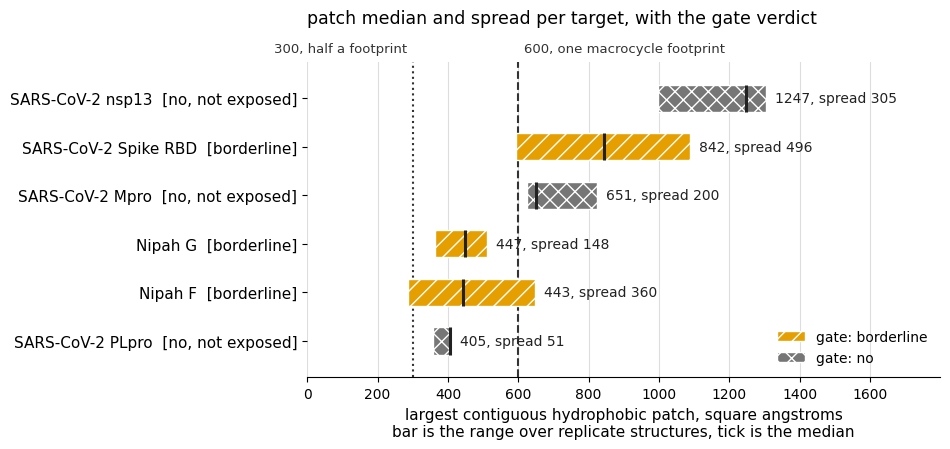


withdrawn, runs/surface_in_ranker.json
  No, in both forms tried, and the change is withdrawn. The markers are computed and reported; they are not scored.

rank-sum p for the recovered targets of each pathogen, lower is better:

  SARS-CoV-2   none 0.0014   added 0.0009 (0.7x better)   centred 0.0201 (14.1x worse)
  Nipah virus  none 0.0714   added 0.3929 (5.5x worse)   centred 0.1250 (1.8x worse)

why added fails:
  The term cannot be earned by a candidate with no deposited structure, so every such
  candidate falls below every candidate that has one. That is a penalty for being
  understudied, aimed at exactly the novel targets the system exists to find. SARS-CoV-2's
  spike went from first to fifth on surface_score None; Nipah's p went 0.071 to 0.393.

why centred fails:
  The mirror failure. Centred on the mean of six reference structures, most real candidates
  score below it, so having a structure became the penalty and the top five were again
  everything with no structure. The

In [6]:
# Knob: which contact cutoff of the marker sweep to summarise. The record carries 8.0, 10.0
# and 12.0, all three are printed below whichever is picked, and 10.0 is the conventional
# interface definition. An unknown value prints the available ones instead of guessing.
CONTACT_CUTOFF = 10.0

from hpc_pilots import intake
from hpc_pilots.intake import MACROCYCLE_FOOTPRINT_A2 as FOOTPRINT
import matplotlib.pyplot as plt
import textwrap

mark_rec = record("surface_markers")
gate_rec = record("amenability_gate")
wd_rec = record("surface_in_ranker")

# The marker, and the one comparison the section rests on checked at every cutoff that was
# measured, so "the direction does not depend on the cutoff" is verified when the cell runs
# rather than asserted in prose.
sweep = {b["contact_angstrom"]: b for b in mark_rec["contact_cutoff_sensitivity"]}
cuts = sorted(sweep)
if CONTACT_CUTOFF not in sweep:
    print(f"CONTACT_CUTOFF must be one of {cuts}")
else:
    blk = sweep[CONTACT_CUTOFF]
    print(f"marker, {len(blk['rows'])} structures, one per target, scored at "
          f"{len(cuts)} contact cutoffs")
    print(f"  at {CONTACT_CUTOFF:.0f} angstroms: enzyme mean score {blk['mean_enzyme']:.2f}, "
          f"non-enzyme {blk['mean_non_enzyme']:.2f}, gap {blk['gap']:+.2f}")
    print("  the comparison a macrocycle cares about, patch in square angstroms, at each:")
    for c in cuts:
        a = {r["target"]: r["patch_area"] for r in sweep[c]["rows"]}
        sel = "   <- CONTACT_CUTOFF" if c == CONTACT_CUTOFF else ""
        print(f"    {c:>4.0f} angstroms   Spike RBD {a['Spike RBD']:>6.0f}   Mpro "
              f"{a['Mpro (nsp5)']:>6.0f}   enzyme gap {sweep[c]['gap']:+.2f}{sel}")
    print()

# The gate, with the patch measured over replicate structures of the same domain rather than
# through whichever single entry came back first. Each verdict is recomputed by the repo's
# own gate rather than read out of the record, and `on_area` re-runs it with localisation
# forced to pass, which is what licenses the claim that the axis below is not the verdict.
gate_rows, disagree = [], []
for t in gate_rec["targets"]:
    feat = {"hydrophobic_patch_area": t["patch_median"],
            "patch_area_min": t["patch_range"][0], "patch_area_max": t["patch_range"][1]}
    verdict = intake.amenable({**feat, "surface_exposed": t["exposed"]})
    if verdict != t["gate"]:
        disagree.append(t["target"])
    gate_rows.append({
        "target": t["target"],
        "modality": t["clinical_modality"],
        "exposed": t["exposed"],
        "patch_median": t["patch_median"],
        "low": t["patch_range"][0],
        "high": t["patch_range"][1],
        "spread": t["patch_spread"],
        "gate": verdict,
        "on_area": intake.amenable({**feat, "surface_exposed": True}),
    })
gate_df = pd.DataFrame(gate_rows).sort_values("patch_median").reset_index(drop=True)
# Kept out of the frame so the table stays narrow enough to read on a projector.
on_area = gate_df.pop("on_area")

counts = sorted({int(t["structures_measured"]) for t in gate_rec["targets"]})
print(f"gate, {len(gate_df)} targets, patch median over "
      f"{counts[0] if len(counts) == 1 else f'{counts[0]} to {counts[-1]}'} "
      "structures each, square angstroms")
# The record stores its own verdict, so recomputing it is a check and not a convenience.
print("verdicts recomputed from hpc_pilots.intake.amenable: "
      + (f"all {len(gate_df)} agree with the record" if not disagree
         else "DISAGREE on " + ", ".join(disagree)))
print(f"rule: localisation first, then yes needs the whole range at or above "
      f"{FOOTPRINT:.0f},\n      no needs it all below {0.5 * FOOTPRINT:.0f}, and a range "
      "between the two is borderline whatever the median says")
# The axis is not the verdict, and this line is how you know: the gate consults localisation
# before area, so a refusal can sit anywhere on the chart.
refused = gate_df.target[gate_df.gate == "no"].tolist()
would_pass = gate_df.target[(gate_df.gate == "no") & (on_area == "yes")].tolist()
print(f"refused on localisation: {', '.join(refused) or 'none'}")
if would_pass:
    print(f"  of those, {', '.join(would_pass)} would gate yes on patch area alone")
print()
display(gate_df)

# Okabe-Ito, which stays separable under the common colour-vision deficiencies. The verdict
# is also written into the tick label and carried by a hatch, so nothing in the figure
# depends on the colour being seen.
STYLE = {"yes": ("#0072B2", ""), "borderline": ("#E69F00", "//"), "no": ("#767676", "xx")}

fig, ax = plt.subplots(figsize=(9.6, 4.6))
for y, r in enumerate(gate_df.itertuples()):
    colour, hatch = STYLE[r.gate]
    ax.barh(y, r.high - r.low, left=r.low, height=0.56, color=colour,
            hatch=hatch, edgecolor="white", linewidth=1.0, zorder=3)
    # The median is a tick inside the range, not the end of a bar, because what is drawn
    # here is a measurement spread and not a magnitude growing from zero.
    ax.vlines(r.patch_median, y - 0.28, y + 0.28, color="#222222", lw=2.2, zorder=4)
    ax.text(r.high + 25, y, f"{r.patch_median:.0f}, spread {r.spread:.0f}",
            va="center", ha="left", fontsize=10, color="#222222", zorder=4)

# Both edges of the uncertain band, because the gate is three-valued and a single rule at the
# footprint leaves the two Nipah verdicts looking unexplained.
rules = ((0.5 * FOOTPRINT, f"{0.5 * FOOTPRINT:.0f}, half a footprint", ":", "right", -4),
         (FOOTPRINT, f"{FOOTPRINT:.0f}, one macrocycle footprint", "--", "left", 4))
for x, lab, ls, ha, dx in rules:
    ax.axvline(x, color="#333333", ls=ls, lw=1.5, zorder=2)
    # Labels above the axes rather than beside the rules, where they collided with the bars,
    # and splayed away from each other, where centring them collided with each other.
    ax.annotate(lab, xy=(x, 1.0), xycoords=("data", "axes fraction"), xytext=(dx, 5),
                textcoords="offset points", ha=ha, va="bottom", fontsize=9.5,
                color="#333333")

ax.set_yticks(range(len(gate_df)))
# The verdict in the tick label, and why, since every "no" here was decided by localisation
# before the area was looked at and the chart would otherwise read as if area decided it.
ax.set_yticklabels([f"{r.target}  [{r.gate}]" if r.exposed
                    else f"{r.target}  [{r.gate}, not exposed]"
                    for r in gate_df.itertuples()], fontsize=11)
ax.set_xlabel("largest contiguous hydrophobic patch, square angstroms\n"
              "bar is the range over replicate structures, tick is the median", fontsize=11)
ax.set_title("patch median and spread per target, with the gate verdict",
             fontsize=12.5, pad=28, loc="left")
ax.set_xlim(0, gate_df.high.max() * 1.38)
ax.set_ylim(-0.75, len(gate_df) - 0.25)
ax.tick_params(axis="x", labelsize=10)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color="#DDDDDD", lw=0.8)
ax.set_axisbelow(True)
seen = [v for v in ("yes", "borderline", "no") if v in set(gate_df.gate)]
ax.legend([plt.Rectangle((0, 0), 1, 1, facecolor=STYLE[v][0], hatch=STYLE[v][1],
                         edgecolor="white") for v in seen],
          [f"gate: {v}" for v in seen], loc="lower right", frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

# The withdrawal, printed under the chart on purpose. The chart is a measurement, and the
# experiment that tried to turn it into a ranking feature failed in both forms it was tried
# in. Printing the record's own prose keeps the chart from reading as a result.
print(f"\nwithdrawn, runs/surface_in_ranker.json\n  {wd_rec['answer']}")
print("\nrank-sum p for the recovered targets of each pathogen, lower is better:\n")
for m in wd_rec["measured"]:
    base = m["p_no_surface"]
    cells = []
    for label, key in (("added", "p_surface_added"), ("centred", "p_surface_centred")):
        ratio = m[key] / base
        cells.append(f"{label} {m[key]:.4f} ({ratio:.1f}x "
                     f"{'worse' if ratio > 1 else 'better'})")
    print(f"  {m['pathogen']:<12} none {base:.4f}   " + "   ".join(cells))
for key in ("why_added_fails", "why_centred_fails", "open"):
    print("\n" + key.replace("_", " ") + ":")
    print(textwrap.fill(wd_rec[key], 92, initial_indent="  ", subsequent_indent="  "))

**The ordering is the finding, and the horizontal axis is not the verdict.** Spike RBD sits
above the main protease on exactly the quantity a macrocycle cares about, which is what the
marker was built to do. The three targets gated `no`, though, are gated on subcellular
localisation, which the gate tests before it consults the area at all, and two of the three
would come back `yes` on area alone, one of them carrying the largest median patch of the six.
That line is printed above the table because it is the easiest thing to get wrong here, and
each tick label names which test the target failed, so a long grey bar is not read as a near
miss.

**The markers did not improve the ranking, in either form tried, and the change was withdrawn.**
The printed rank-sum p-values are why the honest word is "no" rather than "worse": adding the
term improved SARS-CoV-2 slightly while making Nipah several times worse, and centring it made
SARS-CoV-2 an order of magnitude worse. The two failures are one failure in mirror image. A
candidate with no deposited structure cannot earn the term, so whichever way the baseline is
set, having a structure or lacking one becomes the score, and that penalises exactly the
understudied targets this system exists to find. The markers are computed and reported beside
the ranking, and never scored into it.

**What would break this, stated with the result.** Six targets chosen to span the contrast
rather than sampled, one structure per target in the marker sweep and five per domain in the
gate, and no validation anywhere against measured macrocycle binding, because no such labelled
set exists. The borderline band is wide enough that the gate separates clear negatives from
everything else rather than sorting the middle. The open counterexample is printed above: the
largest patch measured anywhere in this work belongs to Nipah's matrix protein, which is not a
drug target, because that surface is an oligomerisation interface buried inside the virion. A
large hydrophobic patch is necessary and not sufficient, and the marker still cannot tell
exposed in a crystal from exposed on a particle.

---
## 2 · Variant ranking

### 2.1 · The surviving result

Arm 2's molecular work is blocked, so the available work was on public canonical-protein
datasets. It produced a result that turns out to be a statement about prediction rather than
about policy.

**Acquisition gain is governed by how densely the candidate pool covers the variable positions
the model has to learn from.** In plainer terms: a weak model fitted on 128 measurements
predicts held-out binding well enough to act on *only when the candidates share sequence
coordinates with the labelled ones*. Where they do not, correlation sits near 0.1 and nothing
downstream helps.

**Why this matters for library design.** The favourable regime is a randomised region of a few
positions over an alphabet, which is what an mRNA display library *is*. A weak predictor is
enough, but there must be one, and whether one can be fitted is knowable in advance.

**Everything below is read from the summary table this repository's own `summarize` command
writes**, over every staged pool, with the `pools` column showing how many each landscape
contributes.

In [7]:
GAIN = ARM2["method gain table"]

if not GAIN.exists():
    print(f"not on this machine: {GAIN.relative_to(ROOT)}\n"
          f"rebuild with:  python -m hpc_pilots summarize")
else:
    g = pd.read_csv(GAIN)
    at128 = g[(g.labels == 128) & (g.policy == "greedy")]

    # Variable positions per landscape, from PREREGISTRATION_COVERAGE.md. This is the
    # coverage axis and it is NOT in the gain table, so it is the one mapping typed by hand.
    # dlg4_pdz3_peptide is absent on purpose: the preregistration does not state a count
    # for it, and inventing one would put a made-up number in a results table.
    POSITIONS = {"grb2_sh3_peptide": 56, "rask_darpin_binding": 187,
                 "spg1_olson_igg_matched": 55, "yap1_ww_peptide": 34,
                 "spg1_olson_igg": 55, "spike_rbd_ace2": 2}

    show = at128.assign(variable_positions=at128.landscape.map(POSITIONS))[[
        "landscape", "protein", "variable_positions", "pool_size", "pools",
        "random_recall", "policy_recall", "mean_paired_gain", "pools_improved",
        "wilcoxon_p"]].sort_values("mean_paired_gain", ascending=False)

    print("greedy acquisition vs random, at a 128-label budget, paired per pool\n")
    display(show.reset_index(drop=True))
    print("\nmean_paired_gain is per-pool greedy recall minus random recall, then averaged.")
    print("A blank variable_positions means the preregistration states no count for it.")

greedy acquisition vs random, at a 128-label budget, paired per pool



,landscape,protein,variable_positions,pool_size,pools,random_recall,policy_recall,mean_paired_gain,pools_improved,wilcoxon_p
0,spg1_olson_igg_matched,Streptococcal protein G B1 domain,55.0,512,20,0.2228,0.5434,0.3206,18,0.0001
1,yap1_ww_peptide,YAP1 WW domain,34.0,512,18,0.2628,0.5064,0.2436,17,0.0003
2,grb2_sh3_peptide,GRB2 SH3 domain,56.0,512,20,0.2750,0.5115,0.2365,19,0.0001
3,rask_darpin_binding,KRAS,187.0,512,20,0.2558,0.4288,0.1731,14,0.0048
4,spg1_olson_igg,Streptococcal protein G B1 domain,55.0,4096,20,0.0280,0.1427,0.1146,14,0.0032
5,dlg4_pdz3_peptide,PSD-95 PDZ3 domain,NaN,256,5,0.6615,0.6769,0.0154,4,NaN
6,spike_rbd_ace2,SARS-CoV-2 spike receptor-binding do...,2.0,512,6,0.2699,0.2800,0.0101,2,NaN



mean_paired_gain is per-pool greedy recall minus random recall, then averaged.
A blank variable_positions means the preregistration states no count for it.


**The result is legible in that one table.** The four landscapes with a few dozen
variable positions over a 512-candidate pool gain between +0.11 and +0.32 against random, each
improving in 14 or more pools at a Wilcoxon p of 0.005 or below. The spike receptor-binding
domain pool, which varies only **2** positions, gains +0.010 and improves in 2 of 6 pools. Same
budget, same acquisition rule, same pool size. What differs is whether the candidates share
sequence coordinates with the labelled ones.

The PDZ3 row is the honest outlier and worth naming before anyone else does: its gain is +0.015
on 5 pools with no p-value, because at a 128-label budget on a 256-candidate pool the policy has
already labelled half the pool and random recall is 0.66. There is almost no headroom left to
win, which is a statement about that pool's geometry and not about acquisition.



### 2.2 · Tested by intervention

**Correlation across the staged landscapes could not establish the claim, so it was tested by
intervening in both directions with everything else held fixed.** Narrow an influenza H3
haemagglutinin scan to a few variable positions per pool, change nothing else, and a gain
appears where the pathogen case had looked like a failure. Re-encode the GB1 double mutants as
(position-pair, residue-pair), a lossless bijection that keeps the variants, the hidden scores
and the combinatorial structure but stops pool members sharing feature levels, and the gain goes
away. The mechanism was then put to a prediction written down and committed before the replays
were run, on two proteins unrelated to anything it was found on.

**Both interventions were run with `hpc_pilots.binding.replay`, which committed a result table
and not per-pool records, so neither is recomputable from `runs/` and neither is restated here.**
What this cell computes instead is the standing evidence for the same mechanism: the eight
landscapes staged at the matched geometry, the preregistered replication scored against its
registered thresholds, and the landscape-level permutation test. To put the interventions
themselves back on a computable footing, re-run the two constructions with `record=True` and
commit their pools.

**Two columns inside the computed table are quoted rather than computed, and are labelled as
such.** Variable positions and in-pool surrogate Spearman both come from the preregistration's
predictor table, the Spearman figures because they were measured before the replays and were
never written into a record. They are the coverage axis the table is read against, so the cell
parses them out of the document rather than retyping them, and they move if the document moves.

**The claim that the prediction came first is a claim about commit order rather than about any
number**, and the check is `git log --follow PREREGISTRATION_COVERAGE.md`, which this notebook
does not run because it is not something it can read out of a record.

In [8]:
from itertools import combinations

# One knob: how many pools the registered criterion is scored over. The preregistration was
# written for 10, so 10 is the number its prediction may fairly be judged against. Set this to
# 20 to score every staged pool instead, which is the basis the summary table in 2.1 uses.
FIRST_N = 10

# The registered thresholds. They are prose in PREREGISTRATION_COVERAGE.md, "The prediction",
# item 1 (at least +0.15, improving in at least 7 of 10 pools), and not a field in any record or
# a cell in any table, so they are typed here. A regex over an English sentence would break the
# first time the sentence is reworded, which is a worse failure than naming the source.
REG_GAIN, REG_IMPROVED = 0.15, 7 / 10

PRE = ROOT / "PREREGISTRATION_COVERAGE.md"             # tracked, present in a fresh clone
POOLED = [RUNS / "summary" / "method_metrics.csv",     # gitignored, one row per pool per budget
          RUNS / "summary" / "target_metrics.csv"]


def pipe_rows(path):
    """Every markdown pipe-table row in a file, as cells with bold and code markers removed."""
    for line in path.read_text().splitlines():
        s = line.strip()
        if s.startswith("|") and set(s) - set("|-: "):
            yield [c.replace("**", "").replace("`", "").strip() for c in s.strip("|").split("|")]


if not all(p.exists() for p in POOLED):
    print("not on this machine: "
          + ", ".join(str(p.relative_to(ROOT)) for p in POOLED if not p.exists())
          + "\nrebuild with: python -m hpc_pilots summarize")
else:
    per = pd.concat([pd.read_csv(p) for p in POOLED])
    # pool_size 512 is the matched geometry the whole comparison is defined at, and selecting on
    # it picks out exactly the eight landscapes: PDZ3 was staged at 256 and GB1-Olson at 4096,
    # so neither belongs in the split, and neither has to be excluded by name here.
    per = per[(per.labels == 128) & (per.delay == 0) & (per.pool_size == 512)]
    rec = per.pivot_table(index=["landscape", "pool"], columns="policy", values="top_recall")

    # Variable positions and in-pool surrogate Spearman, read out of the predictor table in
    # PREREGISTRATION_COVERAGE.md rather than typed the way 2.1 types its POSITIONS dict. Both
    # columns are quoted, not computed: the Spearman figures were measured before the replays and
    # never written into a record, and the records carry metrics over the pools, not the pools.
    pred = {r[0]: (int(r[1]), float(r[2])) for r in pipe_rows(PRE)
            if len(r) == 4 and r[1].isdigit()}
    # Which two landscapes the preregistration named for replication. Names only: the cell scores
    # them against the registered thresholds from the records rather than against a reported gain.
    replication = [r[0] for r in pipe_rows(PRE) if len(r) == 5 and r[0] in pred]

    rows = []
    for ls, g in rec.groupby(level="landscape"):
        g = g.sort_index()
        gain = g.greedy - g.random
        head = gain.head(FIRST_N)
        rows.append({
            "landscape": ls,
            "positions": pred[ls][0],
            "spearman": pred[ls][1],
            "gain_all": round(gain.mean(), 4),
            "pools_all": f"{int((gain > 0).sum())}/{len(gain)}",
            f"gain_{FIRST_N}": round(head.mean(), 4),
            f"pools_{FIRST_N}": f"{int((head > 0).sum())}/{len(head)}",
            "diverse": round((g.diverse - g.random).mean(), 4),
        })
    comp = pd.DataFrame(rows).sort_values("gain_all", ascending=False).reset_index(drop=True)
    byname = comp.set_index("landscape")

    print("computed here  ·  greedy minus random top-5% recall on the same pool, 128 labels,")
    print("zero delay, every landscape staged at the matched 512-candidate geometry. positions")
    print("and spearman are quoted from the preregistration's predictor table and labelled below;")
    print("diverse is the same gain for the no-surrogate arm.\n")
    display(comp)

    # Provenance of the records behind that table, read out of each record rather than asserted.
    # It is not one clean batch: three files were written later from a dirty tree, and one of the
    # three is in the greedy column, so the table is named with that caveat attached.
    files = list(per.file.unique())
    batches = {}
    for f in files:
        q = json.loads((ROOT / f).read_text())["provenance"]
        key = q["git_commit"][:8] + (" dirty" if q["git_dirty"] else "")
        batches.setdefault(key, []).append((q["recorded_at_utc"], f))
    print(f"\nprovenance, read out of each of the {len(files)} records behind that table:")
    for commit, v in sorted(batches.items(), key=lambda kv: -len(kv[1])):
        when = sorted(t for t, _ in v)
        print(f"   {len(v):4d} records   commit {commit:15s} {when[0][:10]}  "
              f"{when[0][11:19]} to {when[-1][11:19]} UTC")
        if len(v) <= 4:
            for _, f in sorted(v, key=lambda x: x[1]):
                print(f"                  {f}")

    print(f"\nthe registered criterion, gain at least +{REG_GAIN:.2f} improving in at least "
          f"{REG_IMPROVED:.0%} of pools,\nscored over the first {FIRST_N} pools, from the "
          f"records:")
    for ls in replication:
        got, n = (int(x) for x in byname.loc[ls, f"pools_{FIRST_N}"].split("/"))
        g = byname.loc[ls, f"gain_{FIRST_N}"]
        print(f"   {ls:22s} {g:+.4f}  {got}/{n} pools   "
              f"{'pass' if g >= REG_GAIN and got / n >= REG_IMPROVED else 'FAIL'}")

    # The landscape, not the pool, is the independent unit, so the only test the committed
    # records can carry is the exact permutation over the eight landscape labels. More than two
    # variable positions against exactly two is the split, and it happens to fall 4 against 4.
    v, k = list(comp.gain_all), int((comp.positions > 2).sum())
    hi, lo = comp.gain_all[comp.positions > 2], comp.gain_all[comp.positions == 2]
    obs = hi.mean() - lo.mean()
    splits = [sum(c) / k - (sum(v) - sum(c)) / (len(v) - k) for c in combinations(v, k)]
    hits = sum(s >= obs - 1e-9 for s in splits)
    print(f"\n{k} landscapes vary more than two positions and gain {hi.min():+.3f} to "
          f"{hi.max():+.3f};\nthe other {len(v) - k} vary two and gain {lo.min():+.3f} to "
          f"{lo.max():+.3f}. The ranges do not overlap.")
    print(f"exact one-sided permutation over landscape labels: p = {hits}/{len(splits)} = "
          f"{hits / len(splits):.3f}, the floor of a {k}-against-{len(v) - k} design.")

computed here  ·  greedy minus random top-5% recall on the same pool, 128 labels,
zero delay, every landscape staged at the matched 512-candidate geometry. positions
and spearman are quoted from the preregistration's predictor table and labelled below;
diverse is the same gain for the no-surrogate arm.



,landscape,positions,spearman,gain_all,pools_all,gain_10,pools_10,diverse
0,spg1_olson_igg_matched,55,0.695,0.3206,18/20,0.3373,10/10,0.0288
1,yap1_ww_peptide,34,0.345,0.2436,17/18,0.2000,9/10,0.0107
2,grb2_sh3_peptide,56,0.455,0.2365,19/20,0.2423,10/10,-0.0385
3,rask_darpin_binding,187,0.675,0.1731,14/20,0.2077,8/10,0.0000
4,ha_h3,2,0.075,0.0327,11/20,0.0308,6/10,-0.0154
5,mpro,2,0.091,0.0269,6/10,0.0269,6/10,0.0077
6,ha_h1,2,0.119,0.0121,9/19,0.0423,6/10,0.0061
7,spike_rbd_ace2,2,0.112,0.0101,2/6,0.0101,2/6,0.0049



provenance, read out of each of the 532 records behind that table:
    529 records   commit e40adbc7        2026-10-20  19:31:21 to 19:34:32 UTC
      3 records   commit 34de5a19 dirty  2026-10-20  20:03:31 to 20:05:53 UTC
                  runs/method/yap1_ww_peptide_ucb_pool00_delay0.json
                  runs/targets/mpro_greedy_pool02_delay0.json
                  runs/targets/mpro_ucb_pool00_delay0.json

the registered criterion, gain at least +0.15 improving in at least 70% of pools,
scored over the first 10 pools, from the records:
   grb2_sh3_peptide       +0.2423  10/10 pools   pass
   rask_darpin_binding    +0.2077  8/10 pools   pass

4 landscapes vary more than two positions and gain +0.173 to +0.321;
the other 4 vary two and gain +0.010 to +0.033. The ranges do not overlap.
exact one-sided permutation over landscape labels: p = 1/70 = 0.014, the floor of a 4-against-4 design.


**The replication holds on the records.** Both registered criteria pass on both landscapes at
the geometry the prediction was written for, +0.242 on the GRB2 SH3 domain improving in 10 of 10
pools and +0.208 on KRAS against the DARPin in 8 of 10, against a registered floor of +0.15 and 7
of 10. Those two figures are computed by the cell above from the per-pool records, not quoted.

**The landscape-level statement survives too.** The four landscapes varying more than two
positions gain +0.173 to +0.321, the four varying two positions gain +0.010 to +0.033, the ranges
do not overlap, and the exact one-sided permutation over landscape labels returns 1 of 70
arrangements, p = 0.014. That is the floor of a four-against-four design rather than a small
p-value arrived at by chance, and it is the strongest form the committed records can carry,
because the landscape and not the pool is the independent unit.

**Three qualifications travel with it, and none of them is a footnote.** The split is drawn on a
quoted column, so the test inherits the preregistration's position counts. §3 of the adjudication
records that a plain ridge on the same features beats this forest on every landscape and flips
one low-coverage landscape positive, so the non-overlap is a statement about one surrogate rather
than about the feature set. And the provenance block names three records written from a dirty
tree half an hour after the other 529, one of which sits in the greedy column, which is a reason
not to treat any single cell of that table as settled.

### 2.3 · What Arm 2 is blocked on

**The blockage is a table of nulls, and this cell prints that table rather than asserting it.**
`hpc_pilots/chemistry.py` holds a block registry: the canonical residues plus a handful of
non-canonical block classes the ribosome is reported to accept, taken from the
genetic-code-reprogramming literature and not from a catalog. The module declares in its own
`PENDING_FIELDS` tuple which fields a platform export would supply, and the cell counts how many
of those cells are actually filled. Nothing in that count is typed here, so on the day the export
lands and one column fills, this section stops making the claim by itself.

**The registry is wired into one tool, and one tool is not an experiment.**
`chemistry.library_spec` is a registered tool and the only one an `emergency` action can
dispatch. It returns a library definition, which is a fixed chloroacetyl initiator, a randomised
region, a closing cysteine and a count of the sequences the definition admits. It produces no
evidence, it is uncitable by construction, and no member of any library it defines has been
synthesised or measured.

**The placeholder for this section said the macrocycle chemistry is wired into no experiment,
and that was too strong, so the cell checks that too.** One staged landscape is a cyclic peptide
library over named non-canonical monomers with structures attached, and it does carry an
experiment: hold a monomer out of training and ask whether a surrogate can rank a library member
built from a block it has never seen measured. That experiment has run, and the repository's one
known failing test is inside it, so it belongs here rather than being left for someone to find.

In [9]:
# One knob: any code the registry holds, a canonical letter like "W" or a block like "NMe-Gly".
SHOW_BLOCK = "ClAc-D-Tyr"

from hpc_pilots import chemistry, emergency, tools

# The registry is imported rather than read back from `data/processed/chemistry/registry.json`,
# which `python -m hpc_pilots chemistry` writes and `.gitignore` excludes. Importing the module
# is both the authoritative source and the one that works in a fresh clone.
blocks = chemistry.registry()
pending = list(chemistry.PENDING_FIELDS)
canonical = sum(1 for b in blocks if b["block_class"] == "canonical")

census = pd.DataFrame([{
    "field": f,
    "supplied_by": "platform export" if f in pending else "this module",
    "populated": sum(1 for b in blocks if b.get(f) is not None),
    "null": sum(1 for b in blocks if b.get(f) is None),
} for f in blocks[0]])

print(f"block registry : {len(blocks)} blocks, {canonical} canonical and "
      f"{len(blocks) - canonical} non-canonical classes")
print(f"pending cells  : {census[census.supplied_by == 'platform export'].null.sum()} null "
      f"of {len(blocks) * len(pending)}\n")
display(census)

row = next((b for b in blocks if b["code"] == SHOW_BLOCK), None)
print(f"\nSHOW_BLOCK = {SHOW_BLOCK!r}, every field it carries:")
if row is None:
    print(f"   no such code. the registry holds: {', '.join(b['code'] for b in blocks)}")
else:
    for key, value in row.items():
        print(f"   {key:<26} {'null' if value is None else value}")

# What the registry is reachable through. Taking this from the tool registry and the action
# table rather than from a grep means the count tracks the code.
wired = [t for t in tools.TOOLS.values() if t.entry.startswith("hpc_pilots.chemistry")]
acts = [a for a, names in emergency.ACTION_TOOLS.items()
        if any(t.name in names for t in wired)]
spec = chemistry.library_spec()
print(f"\nwired into : {len(wired)} of {len(tools.TOOLS)} registered tools "
      f"({', '.join(t.name for t in wired)}), reached by the "
      f"{', '.join(acts)} {'action' if len(acts) == 1 else 'actions'}")
print(f"it returns : a definition over {len(spec['elongator_alphabet'])} elongators admitting "
      f"{spec['theoretical_diversity']:,} sequences, "
      f"produces_evidence={wired[0].produces_evidence}\n")

# Both landscape configs are tracked, so this count survives a fresh clone even though the
# runs it refers to do not. `declared` is reported beside `noncanon` on purpose: seven of the
# ten configs carry no `noncanonical` field at all, so reading their silence as a no is a
# judgement, and the audience should be able to see that it is one.
staged = {}
for cfg in ("method", "display"):
    with open(ROOT / "hpc_pilots" / "configs" / f"{cfg}.json") as fh:
        staged.update(json.load(fh)["landscapes"])
declared = [k for k, v in staged.items() if v.get("noncanonical")]
noncanon = [k for k in declared
            if str(staged[k]["noncanonical"]).lower().startswith("yes")]
print(f"landscapes : {len(staged)} staged, {len(declared)} declaring a noncanonical field, "
      f"{len(noncanon)} answering yes ({', '.join(noncanon)})")

tsrc = (ROOT / "hpc_pilots" / "tests" / "test_pilots.py").read_text()
bodies = {}
for chunk in re.split(r"\n(?=def test_)", tsrc):
    head = re.match(r"def (test_\w+)", chunk)
    if head:
        bodies[head.group(1)] = chunk

# Two counts kept deliberately apart. The first is tests that call the chemistry module's own
# functions. The second is tests that only name `chemistry.library_spec` as a stand-in spec
# while testing the tool registry, and folding those in would overstate the chemistry
# coverage many times over. The overlap is printed because one test is in both sets.
own = {n for n, b in bodies.items() if re.search(
    r"(?<![.\w])(registry|library_spec|alphabet|sample_library|encode)\s*\(", b)}
fixture = {n for n, b in bodies.items() if '"chemistry.library_spec"' in b}
landscape = [n for n, b in bodies.items() if noncanon and noncanon[0] in b]
print(f"tests      : {len(bodies)} in the suite, {len(own)} calling the chemistry module "
      f"({len(own & fixture)} of them also a tool-registry test), {len(fixture)} using its "
      f"tool name as a registry fixture, {len(landscape)} naming {noncanon[0]}")

FAILING = "test_a_vocabulary_encoding_cannot_tell_two_unseen_monomers_apart"
body = bodies.get(FAILING, "")
held = re.search(r"held_count=(\d+)", body)
if not body:
    print(f"\n{FAILING} is no longer in the suite; the README's known failure has moved.")
else:
    print(f"\nthe suite's one known failing test is in this area, {FAILING}.\nIts first "
          f"failing assertion, read out of the test file rather than quoted from memory:")
    # The test binds `linear` to the vocabulary-plus-ridge cell, so these are its assertions.
    # Only the first is reported as the failure because pytest stops there; the two after it
    # read `smallest_separation` and `concordance`, which the record stores as null, so they
    # would not pass either. The sibling assertions on the forest cell and on the three
    # descriptor arms all hold.
    for line in body.splitlines():
        if re.search(r"assert\s.*linear\[", line):
            print("   ", line.strip())
            break

# The holdout size comes out of the test too, so the record shown is the one the test scores.
rec = (RUNS / "monomers" / f"{noncanon[0]}_held{int(held.group(1)):02d}.json"
       if held and noncanon else None)
if rec is None:
    print("\nno record to read: the test no longer names a holdout size")
elif not rec.exists():
    print(f"\nnot on this machine: {rec.relative_to(ROOT)}\n"
          f"rebuild with: python -m hpc_pilots monomers --landscape {noncanon[0]} "
          f"--held {held.group(1)}")
else:
    d = json.loads(rec.read_text())
    paired = pd.DataFrame([{
        "encoder": r["encoder"], "model": r["model"], "columns": r["columns"],
        "tied_rate": r["paired"]["tied_rate"],
        "concordance": r["paired"]["concordance"],
        "held_out_spearman": r["held_out_spearman"],
    } for r in d["results"]])
    print(f"\n{d['experiment']} on {d['landscape']}: {d['held_out_count']} monomers held out, "
          f"{d['library_members']} members, {len(d['descriptors'])} descriptors per block")
    display(paired)
    # The two ranges the prose quotes, computed rather than read off the table by eye.
    real = paired[paired.encoder.isin(["descriptor", "both"])].concordance
    shuf = paired[paired.encoder == "descriptor_shuffled"].concordance
    print(f"\nconcordance, grounded arms : {real.min():.2f} to {real.max():.2f}")
    print(f"concordance, shuffled      : {shuf.min():.2f} and {shuf.max():.2f}  "
          f"(chance is 0.50)")

block registry : 29 blocks, 20 canonical and 9 non-canonical classes
pending cells  : 232 null of 232



,field,supplied_by,populated,null
0,code,this module,29,0
1,block_class,this module,29,0
2,role,this module,29,0
3,stereochemistry,this module,29,0
4,source,this module,29,0
5,chemical_identifier,platform export,0,29
6,ccd_code,platform export,0,29
7,smiles,platform export,0,29
8,stereochemistry_descriptor,platform export,0,29
9,molecular_weight,platform export,0,29



SHOW_BLOCK = 'ClAc-D-Tyr', every field it carries:
   code                       ClAc-D-Tyr
   block_class                chloroacetyl initiator
   role                       initiator
   stereochemistry            D
   source                     Katoh & Suga 2022 block class; platform availability unverified
   chemical_identifier        null
   ccd_code                   null
   smiles                     null
   stereochemistry_descriptor null
   molecular_weight           null
   reprogrammed_codon         null
   rosetta_params             null
   rotamer_library            null

wired into : 1 of 10 registered tools (chemistry.library_spec), reached by the invoke_design_tool action
it returns : a definition over 25 elongators admitting 158,945,703,125 sequences, produces_evidence=False

landscapes : 10 staged, 3 declaring a noncanonical field, 1 answering yes (thrombin_cyclic)
tests      : 191 in the suite, 3 calling the chemistry module (1 of them also a tool-registry test), 24

,encoder,model,columns,tied_rate,concordance,held_out_spearman
0,vocabulary,forest,78,1.0,NaN,0.3294
1,vocabulary,ridge,78,1.0,NaN,0.3889
2,descriptor,forest,66,0.0,0.4984,0.3299
3,descriptor,ridge,66,0.0,0.4734,0.1419
4,both,forest,144,0.0,0.4922,0.3472
5,both,ridge,144,0.0,0.4734,0.2062
6,descriptor_shuffled,forest,66,0.0,0.4966,0.2678
7,descriptor_shuffled,ridge,66,0.0,0.5416,0.2732



concordance, grounded arms : 0.47 to 0.50
concordance, shuffled      : 0.50 and 0.54  (chance is 0.50)


**Read the null column.** Every field the module writes itself is populated for all 29 blocks,
and every field that would come from the platform is null for all 29, which is 232 empty cells
out of 232. `rosetta_params` and `rotamer_library` are two of those columns, and their being
empty is what "the physics-based non-canonical track is untouched" means in practice: there are
no parameters to run physics with. The block printed underneath is the initiator the default
library fixes, and it is the strongest case rather than the weakest, because the chloroacetyl
initiators are the part of this chemistry best described in the literature and they are still
null.

**One tool, 158 billion sequences admitted, and no chemical identifier for any of them.** The
theoretical diversity is a combinatorial count over a definition, not a library that exists, and
the distance between that number and the null column above is the whole of the blockage. Of the
191 tests in the suite, 3 call the chemistry module itself. The 24 that name
`chemistry.library_spec` are tool-registry tests using it as a convenient spec, and counting
those as chemistry coverage would be the easiest available way to overstate this arm.

**The one landscape with real non-canonical chemistry is public data, not an assay this project
ran.** `thrombin_cyclic` is 8,448 cyclic peptides over named monomers with 10 descriptors per
block, taken from a published campaign and staged from the authors' own repository, so it is the
measurement that reconciles this section with the outline's line about nothing being measured
here: nothing has been measured by us. It is also the only place in this repository where a
macrocycle representation meets a measured endpoint, and its result is a structural blindness and
then a null. A one-hot vocabulary gives two members differing only in which unseen monomer they
carry the identical prediction, tied rate 1.0, and grounding the position in measured structure
removes the tie but orders those pairs at chance, concordance 0.47 to 0.50 against shuffled
controls at 0.50 and 0.54. The record is gitignored like the rest of Arm 2's runs, so a fresh
clone prints the guard instead of the table.

**The failing test is a disagreement between the test and the record, and it is open rather than
patched.** The test expects the ridge arm on vocabulary features to separate nearly every pair,
reasoning that regularisation fixes an unseen column's coefficient at something small and
non-zero. The record says tied rate 1.0 for that arm as well, and running that one test
reproduces 1.0, so the record is current and the disagreement is live: either the expectation is
stale or the design matrix is back at a precision where the difference rounds away. Naming it
here is cheaper than having an audience find it in a test run.

**That blockage is the critical path, not a line in a risk table.** It is also why the arm above
is the one with results: when the molecular work could not proceed, decision-policy work on
public data could.

---
## 3 · What to say about this

There are three claims here that the repository can defend out of its own records, and one
caveat that belongs in the same breath as the third rather than in a risk table further down.

**Arm 1 selects by reachability, which is a different question from relevance.** A tool is
callable because its inputs exist in the state, not because its summary matches the query. That
is not a refinement, it is the difference between a selector that works and one that returns
nothing, and the earlier text-matching retriever was measured as returning nothing at this
scale. §1.1 computes the consequence live rather than asserting it: from a bare genome accession
five of ten tools are callable, identification unlocks exactly the five that are not, and the
dependency graph therefore has a single bottleneck.

**That arm runs against the real endpoints, and the calls are auditable rather than merely
reported.** §1.2 dispatches through the project's own tool layer and shows what each call
actually spent beside what its spec declared, which is the comparison that caught two registered
specs claiming a zero cost while reaching four public databases. The same honesty runs through
the recorded work: eight experiments across three virus families and one bacterium, two of them
withdrawals and one of those the withdrawal of a headline claim, with §1.3 reading each record's
own answer field so the count is checkable instead of asserted.

**Arm 2 has a condition for when acquisition works, and it was established by intervention
rather than by correlation.** Narrowing the candidate pool recovers the whole effect on the
pathogen case that had looked like a failure, and destroying feature sharing while holding the
variants, the hidden scores and the combinatorial structure fixed removes it entirely. Both
directions, everything else held constant, followed by a replication on two unrelated proteins
against a prediction committed to the repository before the replays were run. One qualification
travels with that claim and should be said in the same breath: the two intervention runs
committed a result table rather than per-pool records, so neither is recomputable from `runs/`
and §2.2 does not restate their figures. What does reproduce is the standing evidence for the
same mechanism, which is that the preregistered replication passes both registered criteria on
both landscapes, and that across the eight staged landscapes the gain is large where coverage is
dense and absent where it is not, with the two ranges not overlapping.

**The caveat goes with that third claim and not at the end of the talk.** Every landscape behind
the result is canonical residues on a folded protein domain. No macrocycle and no non-canonical
residue has been measured anywhere in this repository. Arm 2 is blocked on the SynX campaign
export, §2.3 enumerates the null chemistry fields out of the repository rather than asserting
them, and that blockage is the critical path.

Put plainly, the allocation layer runs against live endpoints and reports its negative results in
the same records as its positive ones, while the molecular arm, which is what the project is
actually for, has a sharp and preregistered condition for when binding is learnable from a
handful of labels, established on the wrong molecule class. That condition says the favourable
regime is a randomised region of a few positions over an alphabet, which is exactly what an mRNA
display library is, so the result points at the right target even though nothing has yet tested
it there. What the project needs next is not another public-data study, it is the campaign
export.